# Homework 5 solution

Monte Carlo methods.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Question 1.1: inverse-transform sampling

In [2]:
N = 20_000
rng = np.random.default_rng(123)
x_exp = -np.log(1 - rng.random(N)) / 2
pd.DataFrame({'Empirical': [x_exp.mean(), x_exp.var(ddof=1), (x_exp > 2).mean()],
              'Theoretical': [1/2, 1/4, np.exp(-4)]},
             index=['Mean', 'Variance', 'P(X > 2)'])

,Empirical,Theoretical
Mean,0.495349,0.500000
Variance,0.249005,0.250000
P(X > 2),0.017800,0.018316


The empirical moments and tail probability are close to their theoretical values. The tail probability has more visible Monte Carlo variation because only about $N e^{-4}$ observations are expected above 2.

## Question 1.2: acceptance--rejection sampling

The density $6x(1-x)$ is maximized at $x=1/2$, where it equals $3/2$. Thus the smallest envelope constant is $M=3/2$, and the theoretical acceptance probability is $1/M=2/3$.

In [3]:
rng = np.random.default_rng(456)
accepted, proposals = [], 0
while len(accepted) < N:
    y = rng.random()
    proposals += 1
    if rng.random() <= 4*y*(1-y):
        accepted.append(y)
x_ar = np.array(accepted)
pd.DataFrame({'Empirical': [proposals, N/proposals, x_ar.mean(), x_ar.var(ddof=1)],
              'Theoretical': [np.nan, 2/3, 1/2, 1/20]},
             index=['Proposals', 'Acceptance rate', 'Mean', 'Variance'])

,Empirical,Theoretical
Proposals,29945.000000,NaN
Acceptance rate,0.667891,0.666667
Mean,0.500246,0.500000
Variance,0.049455,0.050000


The empirical acceptance rate is close to $2/3$, and the accepted sample reproduces the mean and variance of a $\operatorname{Beta}(2,2)$ distribution.

## Question 1.3: multivariate normal generation

In [4]:
rng = np.random.default_rng(789)
mu = np.array([1, -1, 0.5])
Sigma = np.array([[1, .7, .2], [.7, 2, .4], [.2, .4, .5]])
L = np.linalg.cholesky(Sigma)
z = rng.standard_normal((50_000, 3))
x_mvn = mu + z @ L.T
display(pd.DataFrame({'Empirical': x_mvn.mean(0), 'Target': mu},
                     index=['X1', 'X2', 'X3']))
display(pd.DataFrame(np.cov(x_mvn, rowvar=False),
                     index=['X1', 'X2', 'X3'], columns=['X1', 'X2', 'X3']))

,Empirical,Target
X1,0.992952,1.0
X2,-0.997775,-1.0
X3,0.502870,0.5


,X1,X2,X3
X1,1.003811,0.702709,0.202203
X2,0.702709,2.011485,0.401633
X3,0.202203,0.401633,0.499379


The empirical mean and covariance are close to $\mu$ and $\Sigma$. Since $X=\mu+LZ$ and $\operatorname{Cov}(Z)=I$, the transformation gives

$$
\operatorname{Cov}(X)=LIL^\top=LL^\top=\Sigma.
$$

The off-diagonal entries arise because the coordinates share components of $Z$.

## Question 2.1: ordinary Monte Carlo

,N,Estimate,SE,CI lower,CI upper,Absolute error
0,100,0.806675,0.016224,0.774876,0.838473,0.021276
1,1000,0.787405,0.005218,0.777177,0.797633,0.002007
2,10000,0.786498,0.001614,0.783336,0.789661,0.001100
3,100000,0.785411,0.000511,0.784410,0.786412,0.000013


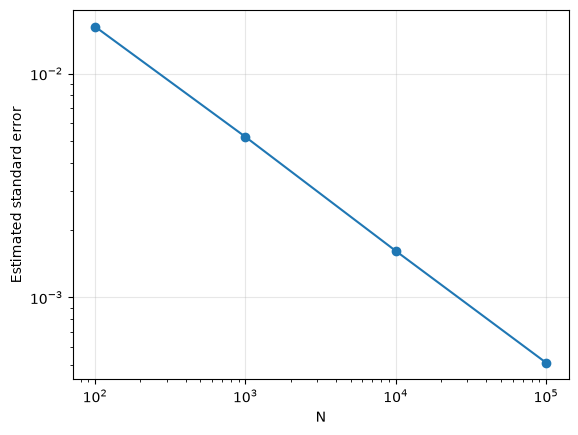

In [5]:
I = np.pi/4
Ns = np.array([100, 1_000, 10_000, 100_000])
h = lambda x: 1/(1 + x**2)
u = np.random.default_rng(1357).random(Ns[-1])
def summarize(values):
    rows = []
    for n in Ns:
        v = values[:n]; est = v.mean(); se = v.std(ddof=1)/np.sqrt(n)
        rows.append([n, est, se, est-1.96*se, est+1.96*se, abs(est-I)])
    return pd.DataFrame(rows, columns=['N', 'Estimate', 'SE', 'CI lower', 'CI upper', 'Absolute error'])
mc = summarize(h(u))
display(mc)
plt.loglog(mc.N, mc.SE, 'o-')
plt.xlabel('N'); plt.ylabel('Estimated standard error'); plt.grid(alpha=.3); plt.show()

The estimate approaches $\pi/4$, and the estimated standard error decreases at the expected $N^{-1/2}$ rate. The absolute error need not decrease at every step because it is random.

## Question 2.2: importance sampling

,N,Estimate,SE,CI lower,CI upper,Absolute error
0,100,0.783156,0.004138,0.775045,0.791267,0.002242
1,1000,0.782786,0.001386,0.780069,0.785502,0.002612
2,10000,0.785063,0.000438,0.784205,0.785921,0.000336
3,100000,0.784917,0.000139,0.784644,0.785189,0.000482


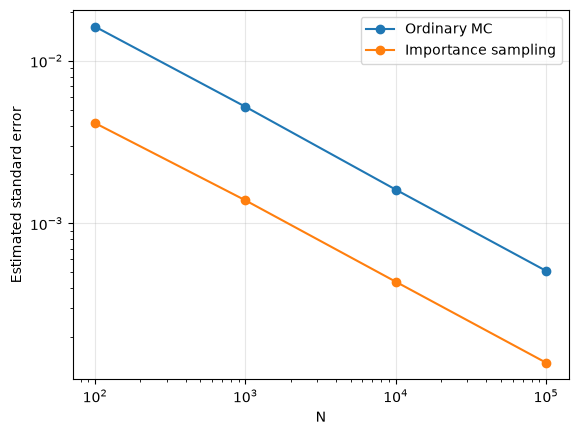

In [6]:
x_is = 2**u - 1
g = 1/(np.log(2)*(1 + x_is))
is_table = summarize(h(x_is)/g)
display(is_table)
plt.loglog(mc.N, mc.SE, 'o-', label='Ordinary MC')
plt.loglog(is_table.N, is_table.SE, 'o-', label='Importance sampling')
plt.xlabel('N'); plt.ylabel('Estimated standard error')
plt.grid(alpha=.3); plt.legend(); plt.show()

The proposal places more probability near zero, where the integrand is larger. It therefore makes $h(X)/g(X)$ more nearly constant and produces a smaller standard error than uniform sampling.

## Question 2.3: composite trapezoidal rule

,N,Trapezoid error,Ordinary MC error,Importance sampling error
0,100,4.251267e-06,0.021276,0.002242
1,1000,4.175013e-08,0.002007,0.002612
2,10000,4.167500e-10,0.001100,0.000336
3,100000,4.166667e-12,0.000013,0.000482


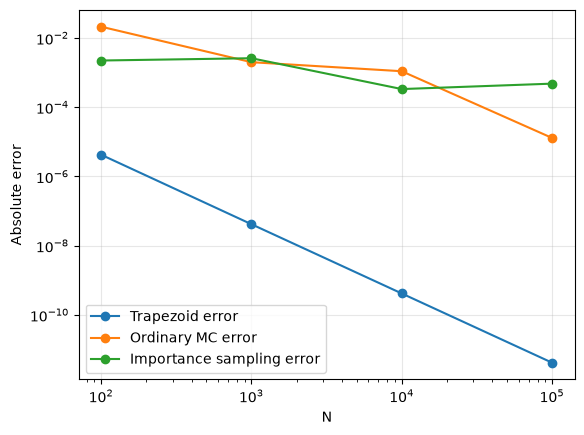

In [ ]:
trap_est = [np.trapezoid(h(x), x) for x in (np.linspace(0, 1, n) for n in Ns)]
comparison = pd.DataFrame({'N': Ns,
    'Trapezoid error': np.abs(np.array(trap_est)-I),
    'Ordinary MC error': mc['Absolute error'],
    'Importance sampling error': is_table['Absolute error']})
display(comparison)
for name in comparison.columns[1:]:
    plt.loglog(Ns, comparison[name], 'o-', label=name)
plt.xlabel('N'); plt.ylabel('Absolute error')
plt.grid(alpha=.3); plt.legend(); plt.show()

For this smooth one-dimensional integrand, the trapezoidal error decreases much faster than either stochastic error. This advantage becomes harder to maintain in high dimensions because a tensor-product grid requires exponentially many evaluation points.